In [ ]:
# PalayCheck AI
# Project Sprint 1: Dataset Exploration and Preparation

# Model: MobileNetV2  
# Framework: TensorFlow/Keras  
# Dataset: Paddy Disease Classification

In [5]:
# Environment Setup
# Import the required libraries and check their versions.

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Python version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
TensorFlow version: 2.21.0
NumPy version: 2.2.4
Pandas version: 3.0.6


In [6]:
# Data Collection
# Set the dataset paths and check if the files exist.

DATASET_DIR = Path.cwd()

TRAIN_DIR = DATASET_DIR / "train_images"
TEST_DIR = DATASET_DIR / "test_images"
TRAIN_CSV = DATASET_DIR / "train.csv"
SAMPLE_SUBMISSION = DATASET_DIR / "sample_submission.csv"

# Verify the dataset files and folders
print("Dataset directory:", DATASET_DIR)
print("Training folder exists:", TRAIN_DIR.exists())
print("Testing folder exists:", TEST_DIR.exists())
print("Training CSV exists:", TRAIN_CSV.exists())
print("Sample submission exists:", SAMPLE_SUBMISSION.exists())

Dataset directory: C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project Sprint 1
Training folder exists: True
Testing folder exists: True
Training CSV exists: True
Sample submission exists: True


In [7]:
# Data Collection
# Load the training CSV and inspect its contents.

train_df = pd.read_csv(TRAIN_CSV)

print("Dataset shape:", train_df.shape)
print("\nColumn names:")
print(train_df.columns.tolist())

print("\nFirst five rows:")
display(train_df.head())

print("\nMissing values:")
print(train_df.isnull().sum())

Dataset shape: (10407, 4)

Column names:
['image_id', 'label', 'variety', 'age']

First five rows:


,image_id,label,variety,age
0,100330.jpg,bacterial_leaf_blight,ADT45,45
1,100365.jpg,bacterial_leaf_blight,ADT45,45
2,100382.jpg,bacterial_leaf_blight,ADT45,45
3,100632.jpg,bacterial_leaf_blight,ADT45,45
4,101918.jpg,bacterial_leaf_blight,ADT45,45



Missing values:
image_id    0
label       0
variety     0
age         0
dtype: int64


Total inference images: 3469

Sample inference image filenames:
200001.jpg
200002.jpg
200003.jpg
200004.jpg
200005.jpg
200006.jpg
200007.jpg
200008.jpg
200009.jpg
200010.jpg


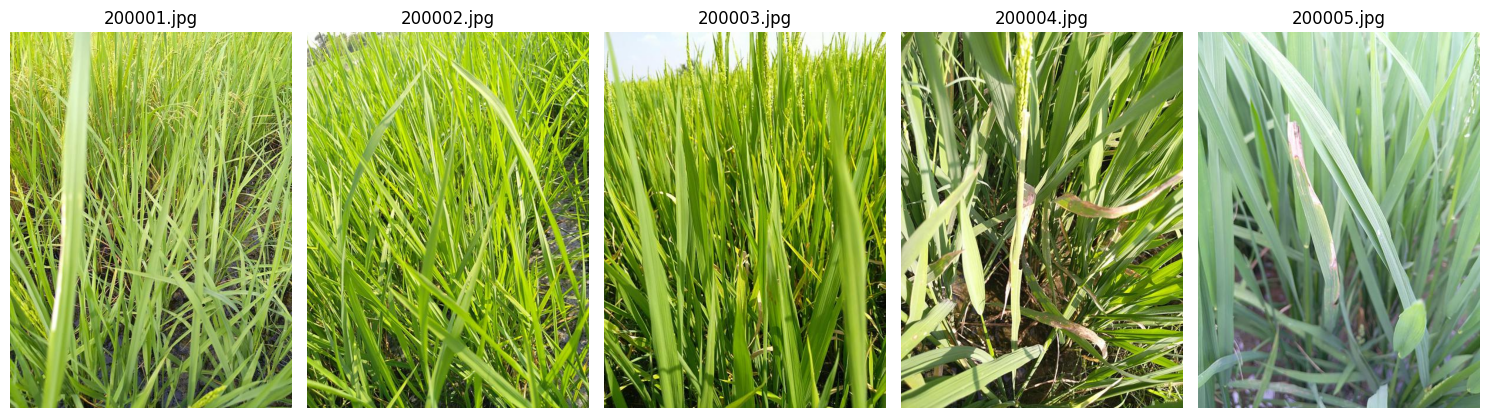

In [8]:
# Data Collection
# Inspect the inference dataset (test_images).

# Get all image files in the test folder
test_image_files = [
    file for file in TEST_DIR.iterdir()
    if file.is_file() and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

# Count the inference images
print("Total inference images:", len(test_image_files))

# Display the first 10 image filenames
print("\nSample inference image filenames:")
for file in test_image_files[:10]:
    print(file.name)

# Display up to 5 sample inference images
sample_test_images = test_image_files[:5]

plt.figure(figsize=(15, 5))

for i, image_path in enumerate(sample_test_images):
    with Image.open(image_path) as img:
        image = img.convert("RGB")

    plt.subplot(1, len(sample_test_images), i + 1)
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
# Image Preprocessing
# Check the dimensions of sample training images.

# Select 10 random images from the training dataset
sample_images = train_df.sample(n=10, random_state=42)

# Display the dimensions of each image
for _, row in sample_images.iterrows():
    image_path = TRAIN_DIR / row["label"] / row["image_id"]

    with Image.open(image_path) as img:
        print(
            f"Image: {row['image_id']} | "
            f"Class: {row['label']} | "
            f"Dimensions: {img.size}"
        )

Image: 110123.jpg | Class: dead_heart | Dimensions: (480, 640)
Image: 103408.jpg | Class: dead_heart | Dimensions: (480, 640)
Image: 106214.jpg | Class: tungro | Dimensions: (480, 640)
Image: 100525.jpg | Class: normal | Dimensions: (480, 640)
Image: 104673.jpg | Class: dead_heart | Dimensions: (480, 640)
Image: 102229.jpg | Class: dead_heart | Dimensions: (480, 640)
Image: 100874.jpg | Class: dead_heart | Dimensions: (480, 640)
Image: 109401.jpg | Class: downy_mildew | Dimensions: (480, 640)
Image: 103165.jpg | Class: blast | Dimensions: (480, 640)
Image: 103529.jpg | Class: blast | Dimensions: (480, 640)


Image: 110123.jpg | Original: (480, 640) | Resized: (224, 224)
Image: 103408.jpg | Original: (480, 640) | Resized: (224, 224)
Image: 106214.jpg | Original: (480, 640) | Resized: (224, 224)
Image: 100525.jpg | Original: (480, 640) | Resized: (224, 224)
Image: 104673.jpg | Original: (480, 640) | Resized: (224, 224)


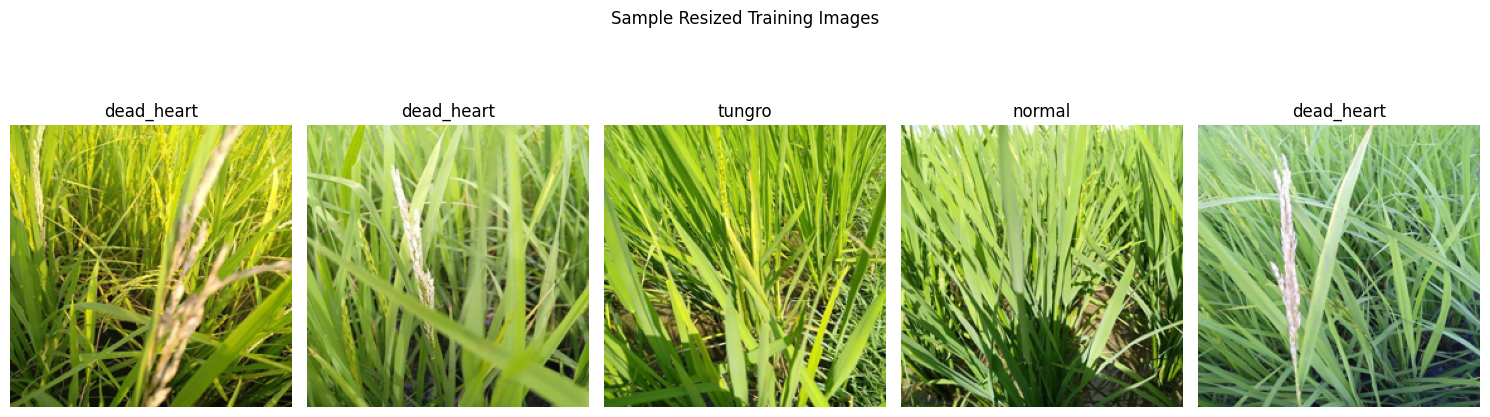

In [10]:
# Image Preprocessing
# Resize training images to 224 x 224 pixels.

IMAGE_SIZE = (224, 224)

# Select 5 sample images from the training dataset
sample_images = train_df.sample(n=5, random_state=42)

# Resize and display each image
plt.figure(figsize=(15, 5))

for i, (_, row) in enumerate(sample_images.iterrows()):
    image_path = TRAIN_DIR / row["label"] / row["image_id"]

    with Image.open(image_path) as img:
        # Convert image to RGB and resize
        resized_img = img.convert("RGB").resize(IMAGE_SIZE)

        # Display resized image
        plt.subplot(1, 5, i + 1)
        plt.imshow(resized_img)
        plt.title(row["label"])
        plt.axis("off")

        print(
            f"Image: {row['image_id']} | "
            f"Original: {img.size} | "
            f"Resized: {resized_img.size}"
        )

plt.suptitle("Sample Resized Training Images")
plt.tight_layout()
plt.show()

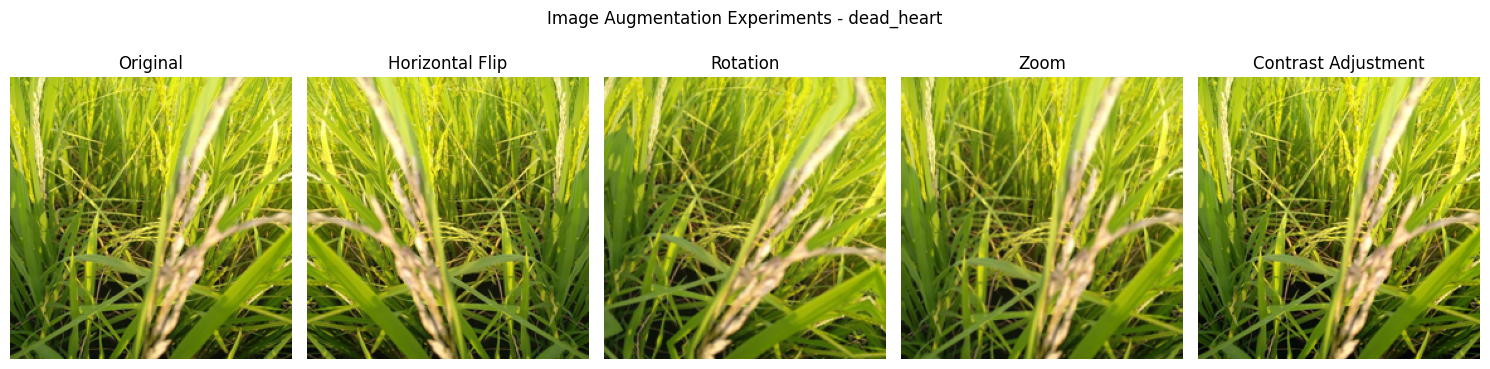

In [11]:
# Image Augmentation
# Experiment with different augmentation techniques.

# Select one sample image from the training dataset
sample_row = train_df.sample(n=1, random_state=42).iloc[0]
image_path = TRAIN_DIR / sample_row["label"] / sample_row["image_id"]

# Load and resize the image
with Image.open(image_path) as img:
    original_image = img.convert("RGB").resize(IMAGE_SIZE)

# Convert the image to a TensorFlow tensor
image_tensor = tf.convert_to_tensor(
    np.array(original_image),
    dtype=tf.float32
)

# Add a batch dimension
image_batch = tf.expand_dims(image_tensor, axis=0)

# Define augmentation techniques
augmentations = {
    "Horizontal Flip": tf.keras.layers.RandomFlip(
        mode="horizontal", seed=42
    ),
    "Rotation": tf.keras.layers.RandomRotation(
        factor=0.1, seed=42
    ),
    "Zoom": tf.keras.layers.RandomZoom(
        height_factor=0.2, width_factor=0.2, seed=42
    ),
    "Contrast Adjustment": tf.keras.layers.RandomContrast(
        factor=0.2, seed=42
    )
}

# Display the original image and augmented versions
plt.figure(figsize=(15, 4))

plt.subplot(1, 5, 1)
plt.imshow(original_image)
plt.title("Original")
plt.axis("off")

for i, (name, layer) in enumerate(augmentations.items(), start=2):
    augmented_image = layer(image_batch, training=True)
    augmented_image = tf.clip_by_value(augmented_image[0], 0, 255)

    plt.subplot(1, 5, i)
    plt.imshow(tf.cast(augmented_image, tf.uint8))
    plt.title(name)
    plt.axis("off")

plt.suptitle(f"Image Augmentation Experiments - {sample_row['label']}")
plt.tight_layout()
plt.show()

In [12]:
# Image Augmentation
# Define augmentation layers to be applied during training.

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        mode="horizontal",
        seed=42
    ),
    tf.keras.layers.RandomRotation(
        factor=0.1,
        seed=42
    ),
    tf.keras.layers.RandomZoom(
        height_factor=0.2,
        width_factor=0.2,
        seed=42
    ),
    tf.keras.layers.RandomContrast(
        factor=0.2,
        seed=42
    )
])

print("Image augmentation layers defined successfully.")

Image augmentation layers defined successfully.


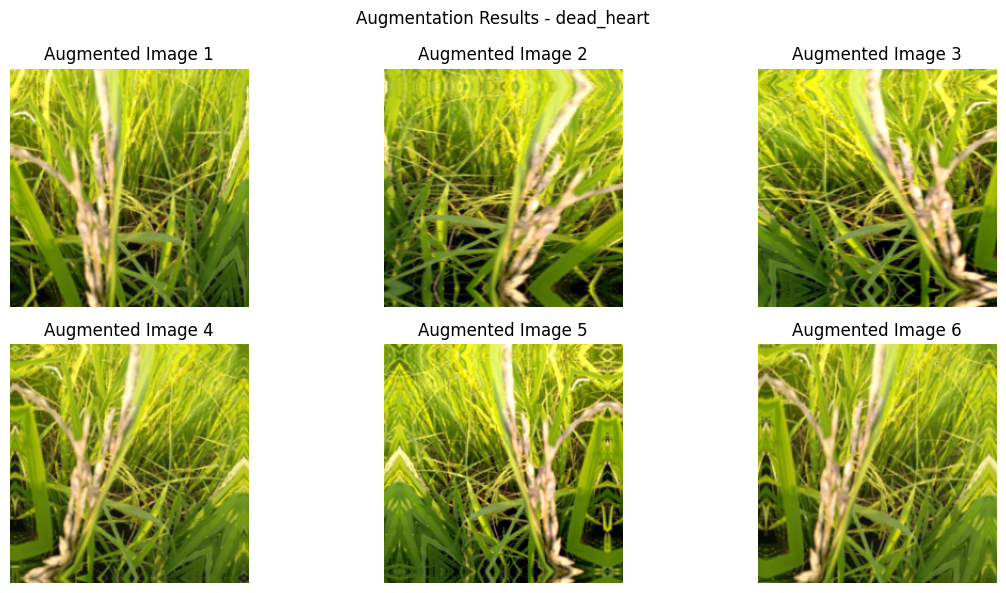

In [13]:
# Visualize Image Augmentation
# Apply augmentation to one sample image only.

# Select one image from the training dataset
sample_row = train_df.sample(n=1, random_state=42).iloc[0]
image_path = TRAIN_DIR / sample_row["label"] / sample_row["image_id"]

# Load and resize the image
with Image.open(image_path) as img:
    original_image = img.convert("RGB").resize(IMAGE_SIZE)

# Convert the image to a TensorFlow tensor
image_tensor = tf.convert_to_tensor(
    np.array(original_image),
    dtype=tf.float32
)

# Add batch dimension
image_batch = tf.expand_dims(image_tensor, axis=0)

# Apply augmentation several times to the same image
plt.figure(figsize=(12, 6))

for i in range(6):
    augmented_image = data_augmentation(
        image_batch,
        training=True
    )[0]

    # Keep pixel values within the display range
    augmented_image = tf.clip_by_value(
        augmented_image, 0, 255
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(tf.cast(augmented_image, tf.uint8))
    plt.title(f"Augmented Image {i + 1}")
    plt.axis("off")

plt.suptitle(f"Augmentation Results - {sample_row['label']}")
plt.tight_layout()
plt.show()

In [14]:
# Data Collection - Inference Dataset
# Inspect the test images and sample submission file.

# Get all image files in the test directory
test_image_paths = sorted([
    path for path in TEST_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

# Load the sample submission file
sample_submission_df = pd.read_csv(SAMPLE_SUBMISSION)

# Display dataset information
print("Inference dataset inspection completed.")
print("Number of test images:", len(test_image_paths))
print("Sample test image filenames:")
for path in test_image_paths[:10]:
    print(path.name)

print("\nSample submission columns:")
print(sample_submission_df.columns.tolist())

print("\nSample submission preview:")
display(sample_submission_df.head())

Inference dataset inspection completed.
Number of test images: 3469
Sample test image filenames:
200001.jpg
200002.jpg
200003.jpg
200004.jpg
200005.jpg
200006.jpg
200007.jpg
200008.jpg
200009.jpg
200010.jpg

Sample submission columns:
['image_id', 'label']

Sample submission preview:


,image_id,label
0,200001.jpg,NaN
1,200002.jpg,NaN
2,200003.jpg,NaN
3,200004.jpg,NaN
4,200005.jpg,NaN


In [17]:
# Image Preprocessing - Training Dataset
# Resize and rename training images.

from pathlib import Path
from PIL import Image

# Define the output directory
PROCESSED_TRAIN_DIR = Path.cwd() / "processed_train_images"
PROCESSED_TRAIN_DIR.mkdir(parents=True, exist_ok=True)

# Set the target image dimensions
IMAGE_SIZE = (224, 224)

# Process and rename each training image
processed_count = 0

for _, row in train_df.iterrows():
    label = row["label"]
    original_filename = row["image_id"]

    # Locate the original image
    image_path = TRAIN_DIR / label / original_filename

    # Create a separate folder for each disease class
    class_dir = PROCESSED_TRAIN_DIR / label
    class_dir.mkdir(parents=True, exist_ok=True)

    # Generate a standardized filename
    new_filename = f"{label}_{processed_count + 1:05d}.jpg"
    output_path = class_dir / new_filename

    # Resize and save the image
    with Image.open(image_path) as img:
        resized_img = img.convert("RGB").resize(
            IMAGE_SIZE,
            Image.Resampling.LANCZOS
        )
        resized_img.save(output_path, format="JPEG", quality=95)

    processed_count += 1

print("Training image preprocessing completed.")
print("Images processed:", processed_count)
print("Output folder:", PROCESSED_TRAIN_DIR)

Training image preprocessing completed.
Images processed: 10407
Output folder: C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project Sprint 1\processed_train_images


In [16]:
# Image Preprocessing - Inference Dataset
# Resize and rename inference images.

from pathlib import Path
from PIL import Image
import pandas as pd

# Define the output directory
PROCESSED_TEST_DIR = Path.cwd() / "processed_test_images"
PROCESSED_TEST_DIR.mkdir(parents=True, exist_ok=True)

# Set the target image dimensions
IMAGE_SIZE = (224, 224)

# Collect inference image files
test_image_paths = sorted([
    path for path in TEST_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

# Store original and processed filenames
test_file_mapping = []
processed_count = 0

# Process and rename each inference image
for image_path in test_image_paths:

    # Generate a standardized filename
    new_filename = f"test_{processed_count + 1:05d}.jpg"
    output_path = PROCESSED_TEST_DIR / new_filename

    # Resize and save the image
    with Image.open(image_path) as img:
        resized_img = img.convert("RGB").resize(
            IMAGE_SIZE,
            Image.Resampling.LANCZOS
        )
        resized_img.save(output_path, format="JPEG", quality=95)

    # Record the original and new filenames
    test_file_mapping.append({
        "original_filename": image_path.name,
        "processed_filename": new_filename
    })

    processed_count += 1

# Save the filename mapping
test_mapping_df = pd.DataFrame(test_file_mapping)
test_mapping_df.to_csv(
    PROCESSED_TEST_DIR / "test_filename_mapping.csv",
    index=False
)

# Display results
print("Inference image preprocessing completed.")
print("Images processed:", processed_count)
print("Output folder:", PROCESSED_TEST_DIR)
print("Filename mapping saved.")

display(test_mapping_df.head())

Inference image preprocessing completed.
Images processed: 3469
Output folder: C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project Sprint 1\processed_test_images
Filename mapping saved.


,original_filename,processed_filename
0,200001.jpg,test_00001.jpg
1,200002.jpg,test_00002.jpg
2,200003.jpg,test_00003.jpg
3,200004.jpg,test_00004.jpg
4,200005.jpg,test_00005.jpg


In [18]:
# Save Sample Augmented Images for Project Sprint 1

from pathlib import Path
from PIL import Image

# Create a folder for the augmented images
AUGMENTED_DIR = Path.cwd() / "sample_augmented_images"
AUGMENTED_DIR.mkdir(parents=True, exist_ok=True)

# Save the original image
original_image.save(AUGMENTED_DIR / "original.jpg")

# Generate and save six augmented images
for i in range(6):
    augmented_image = data_augmentation(
        image_batch,
        training=True
    )[0]

    # Convert to a displayable image
    augmented_image = tf.clip_by_value(
        augmented_image, 0, 255
    )
    augmented_image = tf.cast(
        augmented_image, tf.uint8
    ).numpy()

    # Save the augmented image
    Image.fromarray(augmented_image).save(
        AUGMENTED_DIR / f"augmented_{i + 1}.jpg"
    )

print("Sample augmented images saved successfully.")
print("Output folder:", AUGMENTED_DIR)
print("Number of augmented images:", 6)

Sample augmented images saved successfully.
Output folder: C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project Sprint 1\sample_augmented_images
Number of augmented images: 6
